# MOFinder: 20 frequently reported linkers

Resolve linker names to SMILES and calculate molecular weights. Counts describe positive synthesis records. The default run uses the included validated cache. Set `REFRESH_ONLINE = True` to query public providers for every name. Results are saved under `results/top20_linkers_demo/`.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import HTML, Image, display
from rdkit import Chem
from rdkit.Chem import Draw

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "src" / "smilesearcher").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from smilesearcher.cache import get_cached_smiles, load_cache_json
from smilesearcher.chemistry import molecular_weight
from smilesearcher.models import Resolution
from smilesearcher.resolvers import Resolver

REFRESH_ONLINE = False
OUTPUT = ROOT / "results" / "top20_linkers_demo"
OUTPUT.mkdir(parents=True, exist_ok=True)
source = pd.read_csv(ROOT / "examples" / "top20_linkers_input.csv",
                     keep_default_na=False)
assert len(source) == 20 and source["linker_SMILES_1"].eq("").all()

### Name lookup and molecular weight

Molecular weights use RDKit average atomic weights and are reported in g/mol.

In [2]:
cache = load_cache_json(ROOT / "examples" / "top20_linkers_cache.json")
resolver = Resolver(providers=("pubchem", "cactus", "opsin")) if REFRESH_ONLINE else None
answers = []
try:
    for name in source["linker_1"]:
        if REFRESH_ONLINE:
            answer = resolver.resolve(name)
        else:
            smiles = get_cached_smiles(cache, name)
            answer = Resolution(name, smiles, "example_cache",
                                "found" if smiles else "not_found")
        if answer.status != "found":
            raise RuntimeError(f"No unique structure for {name}: {answer.status}")
        answers.append(answer)
finally:
    if resolver is not None:
        resolver.close()

result = source.copy()
result["linker_SMILES_1"] = [answer.smiles for answer in answers]
result["linker_MW_1"] = result["linker_SMILES_1"].map(molecular_weight)
assert result["linker_MW_1"].notna().all()
if not REFRESH_ONLINE:
    expected = pd.read_csv(ROOT / "examples" / "top20_linkers.csv", keep_default_na=False)
    pd.testing.assert_frame_equal(result, expected, check_dtype=False, rtol=0, atol=1e-6)
result.to_csv(OUTPUT / "linkers.csv", index=False)
(OUTPUT / "lookup_results.json").write_text(
    json.dumps([answer.to_dict() for answer in answers], indent=2), encoding="utf-8")

table = result.rename(columns={"rank": "Rank", "record_count": "Records",
                               "linker_1": "Linker", "linker_SMILES_1": "SMILES",
                               "linker_MW_1": "MW (g/mol)"})
display(HTML(table.to_html(index=False, float_format=lambda value: f"{value:.2f}")))

Rank,Linker,Records,SMILES,MW (g/mol)
1,terephthalic acid,1891,O=C(O)c1ccc(C(=O)O)cc1,166.13
2,"benzene-1,3,5-tricarboxylic acid",1141,O=C(O)c1cc(C(=O)O)cc(C(=O)O)c1,210.14
3,2-methylimidazole,527,Cc1ncc[nH]1,82.11
4,2-aminoterephthalic acid,499,Nc1cc(C(=O)O)ccc1C(=O)O,181.15
5,"2,5-dihydroxyterephthalic acid",316,O=C(O)c1cc(O)c(C(=O)O)cc1O,198.13
6,"biphenyl-4,4'-dicarboxylic acid",293,O=C(O)c1ccc(-c2ccc(C(=O)O)cc2)cc1,242.23
7,fumaric acid,227,O=C(O)/C=C/C(=O)O,116.07
8,isophthalic acid,175,O=C(O)c1cccc(C(=O)O)c1,166.13
9,"2,6-naphthalenedicarboxylic acid",140,O=C(O)c1ccc2cc(C(=O)O)ccc2c1,216.19
10,"2,5-thiophenedicarboxylic acid",116,O=C(O)c1ccc(C(=O)O)s1,172.16


### Molecular structures

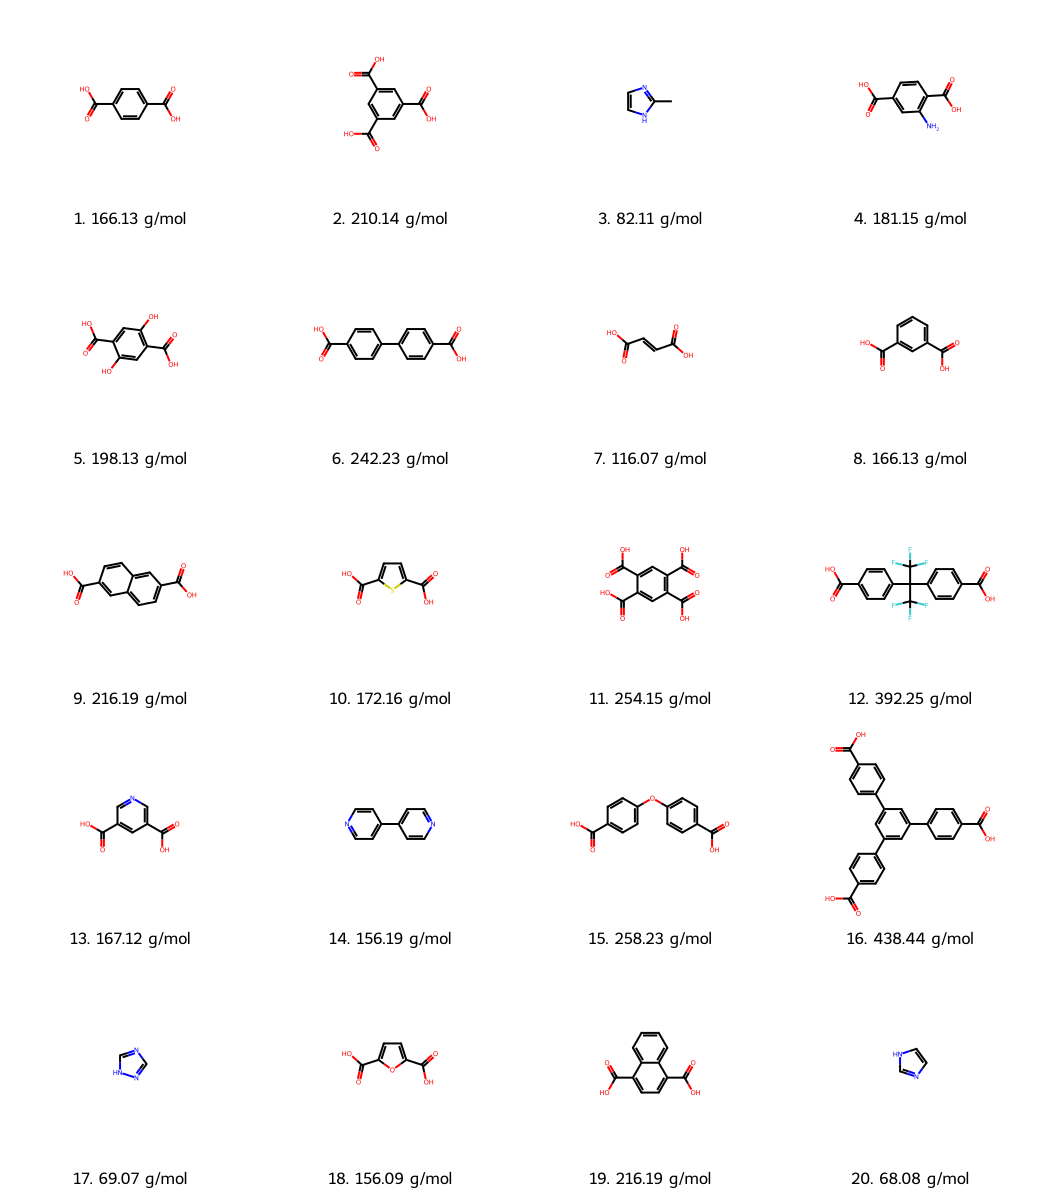

In [3]:
molecules = [Chem.MolFromSmiles(smiles) for smiles in result["linker_SMILES_1"]]
legends = [f"{row['rank']}. {row['linker_MW_1']:.2f} g/mol"
           for _, row in result.iterrows()]
options = Draw.MolDrawOptions()
options.legendFontSize = 16
options.legendFraction = 0.15
grid = Draw.MolsToGridImage(molecules, molsPerRow=4, subImgSize=(260, 240),
                           legends=legends, drawOptions=options, returnPNG=True)
png = grid.data if hasattr(grid, "data") else grid
(OUTPUT / "linker_structures.png").write_bytes(png)
display(Image(data=png, width=900))